<a href="https://colab.research.google.com/github/Youssefessam-hub/portfolio/blob/main/Image_Filters_Applications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2

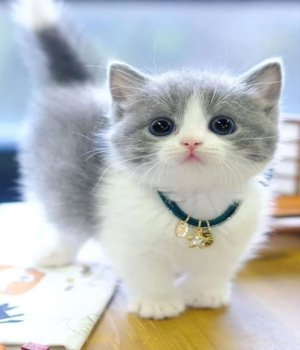

In [ ]:
from google.colab.patches import cv2_imshow

img=cv2.imread("/Cat_image.jpg")
width = 300
height = 350
dimension = (width, height)
img = cv2.resize(img, dimension, interpolation=cv2.INTER_AREA)
cv2_imshow(img)


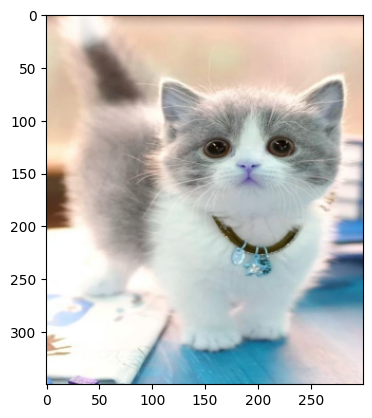

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(img)

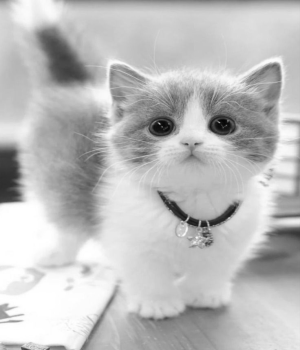

In [ ]:
from google.colab.patches import cv2_imshow

def black_white(img):
    gray_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return gray_image
new_img = black_white(img)
cv2_imshow(new_img)

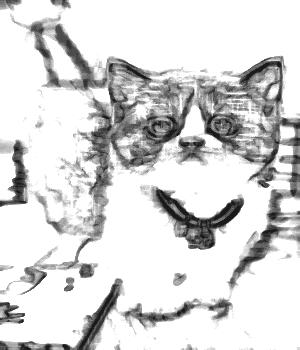

In [ ]:
def pencil_sketch(img, ksize=5):
    blur = cv2.GaussianBlur(img, (ksize, ksize), 0, 0)
    sketch_gray, sketch_color = cv2.pencilSketch(blur, sigma_s=60, sigma_r=0.07, shade_factor=0.05)
    return sketch_gray
new_sketch = pencil_sketch(img)
cv2_imshow(new_sketch)

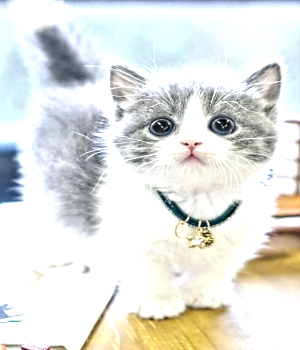

In [ ]:
def HDI(img, level=50,sigma_s=10,sigma_r=0.1):
    bright = cv2.convertScaleAbs(img,beta=level)
    hd_image= cv2.detailEnhance(bright, sigma_s= sigma_s , sigma_r= sigma_r)
    return hd_image
new_hd = HDI(img)
cv2_imshow(new_hd)

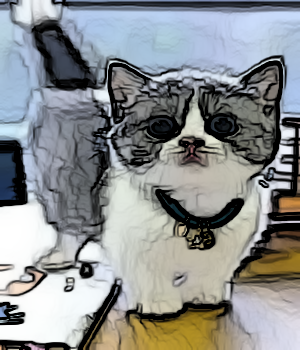

In [ ]:
def style_img(img, ksize=5,sigma_s=10,sigma_r=0.1):
    blur = cv2.GaussianBlur(img,(ksize,ksize),0,0)
    style= cv2.stylization(blur, sigma_s= sigma_s , sigma_r= sigma_r)
    return style
new_style = style_img(img)
cv2_imshow(new_style)

In [ ]:
#Connect with streamlit

%%writefile Filters_APP.py
import streamlit as st
import cv2
import numpy as np

st.title('Filters Application')

def black_white(img):
    gray_image = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return gray_image

def pencil_sketch(img, ksize = 5):
    blur = cv2.GaussianBlur(img, (ksize,ksize), 0,0)
    sketch, _ = cv2.pencilSketch(blur)
    return sketch

def HDR(img, level = 50, sigma_s = 10, sigma_r = 0.1):
    bright = cv2.convertScaleAbs(img, beta = level)
    hd_image = cv2.detailEnhance(bright, sigma_s= sigma_s, sigma_r= sigma_r)
    return hd_image

def Brightness(img, level = 50):
    bright = cv2.convertScaleAbs(img, beta = level)
    return bright

def style_img(img, ksize = 5, sigma_s = 10, sigma_r = 0.1):
    blur = cv2.GaussianBlur(img, (ksize, ksize), 0,0)
    style = cv2.stylization(blur, sigma_s= sigma_s, sigma_r= sigma_r)
    return style


upload = st.file_uploader('Choose an Image...', type = ['png', 'jpg', 'jpeg'])

from PIL import Image

if upload is not None:
    img = Image.open(upload) #read image
    img = np.array(img)

    original_image, output_image = st.columns(2)

    with original_image:
        st.header('Original Image:')
        #show image
        st.image(img, use_container_width = True)

    st.header('Image Filters:')
    options = st.selectbox('Select Filter', ('None', 'black_white', 'pencil_sketch', 'HDR', 'Brightness', 'style_img'))

    if options == 'None':
        output = img

    elif options == 'black_white':
        output = black_white(img)

    elif options == 'pencil_sketch':
        ksize = st.slider('Kerbel Size', 1, 9, 5, step = 2)
        output = pencil_sketch(img, ksize)

    elif options == 'HDR':
        level = st.slider('level', -100, 100, 0, step = 5)
        sigma_s = st.slider('sigma_s', 1, 10, 5, step = 1)
        sigma_r = st.slider('sigma_r', 0.0, 1.0, 0.1, step = 0.1)
        output = HDR(img, level = level, sigma_s= sigma_s, sigma_r= sigma_r)

    elif options == 'Brightness':
        level = st.slider('level', -100, 100, 0, step = 5)
        output = Brightness(img, level = level)

    elif options == 'style_img':
        ksize = st.slider('ksize', 1, 9, 5, step = 2)
        sigma_s = st.slider('sigma_s', 1, 10, 5, step = 1)
        sigma_r = st.slider('sigma_r', 0.0, 1.0, 0.1, step = 0.1)
        output = style_img(img, ksize = ksize, sigma_s= sigma_s, sigma_r= sigma_r)

    with output_image:
        st.header('Output Image:')
        st.image(output, use_container_width = True)

In [ ]:
!pip install -q streamlit

import subprocess
import time

subprocess.Popen([
    "streamlit", "run", "Filters_APP.py",
    "--server.port", "8501",
    "--server.address", "0.0.0.0",
    "--server.enableCORS", "false",
    "--server.enableXsrfProtection", "false"
])
time.sleep(3)

print("The Link...")
!ssh -o StrictHostKeyChecking=no -R 80:localhost:8501 serveo.net

The Link...
Forwarding HTTP traffic from https://c7d5f340a633b19b-34-185-75-170.serveousercontent.com
